<a href="https://colab.research.google.com/github/EllenEufrasio/Algoritmos_e_Logicas_de_Programacao/blob/main/Tarefa04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nome: Ellen Eufrasio de Oliveira
RA: 1131392413021

Profª Luciana Zapparolli
Matéria: Mineração de Dados

Tarefa 04 - Exercício Prático – Visualização de Dados com netflix_titles.csv

A base netflix_titles.csv contém informações sobre os títulos disponíveis na Netflix: tipo
de mídia (filme/série), ano de lançamento, duração, país de origem, gênero, entre outros.
O objetivo é explorar e visualizar esses dados, aplicando técnicas de visualização vistas
em aula.


In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv("https://raw.githubusercontent.com/profzappa/profGit/refs/heads/master/netflix_titles.csv")
display(df.head())

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


**Criar os seguintes gráficos, apresentar os códigos e print do gráfico criado para cada item.**

A. Distribuição dos Tipos de Conteúdo
* Crie um gráfico de barras que mostre a quantidade de Filmes e Séries disponíveis na
base.

B. Países com mais Produções
* Quais são os Top 10 países que mais produziram títulos na Netflix? Crie um gráfico
de barras horizontal.

C. Utilize a IA Gemini para criar um gráfico de barras interativo dos 10 países com
mais produções.

D. Distribuição do Ano de Lançamento
* Construa um histograma mostrando a distribuição dos anos de lançamento dos títulos.

E. Utilize a IA Gemini para criar um gráfico de pizza que represente a proporção de
Filmes (tipo=Filme) por ano de lançamento, considerando somente os anos 2020
e 2021.

F. Transformar o gráfico anterior em rosca.

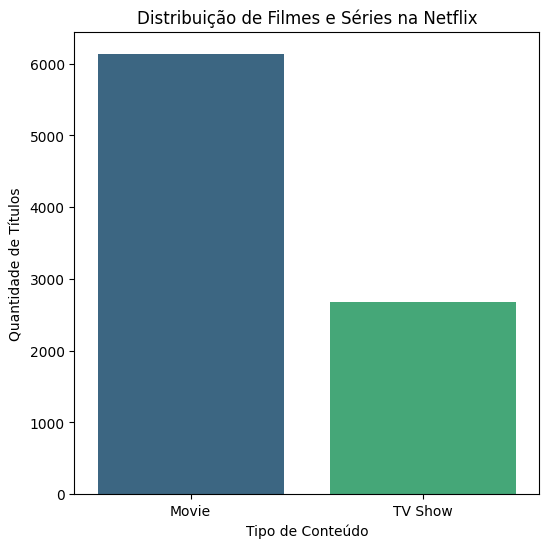

In [ ]:
# A. Distribuição dos Tipos de Conteúdo
# Crie um gráfico de barras que mostre a quantidade de Filmes e Séries disponíveis na base.

# Importaç~pes necessarias
import matplotlib.pyplot as plt
import seaborn as sns

content_counts = df['type'].value_counts().reset_index()
content_counts.columns = ['Tipo', 'Quantidade']

plt.figure(figsize=(6, 6))
sns.barplot(x='Tipo', y='Quantidade', data=content_counts, palette='viridis', hue='Tipo', legend=False)
plt.title('Distribuição de Filmes e Séries na Netflix')
plt.xlabel('Tipo de Conteúdo')
plt.ylabel('Quantidade de Títulos')
plt.show()

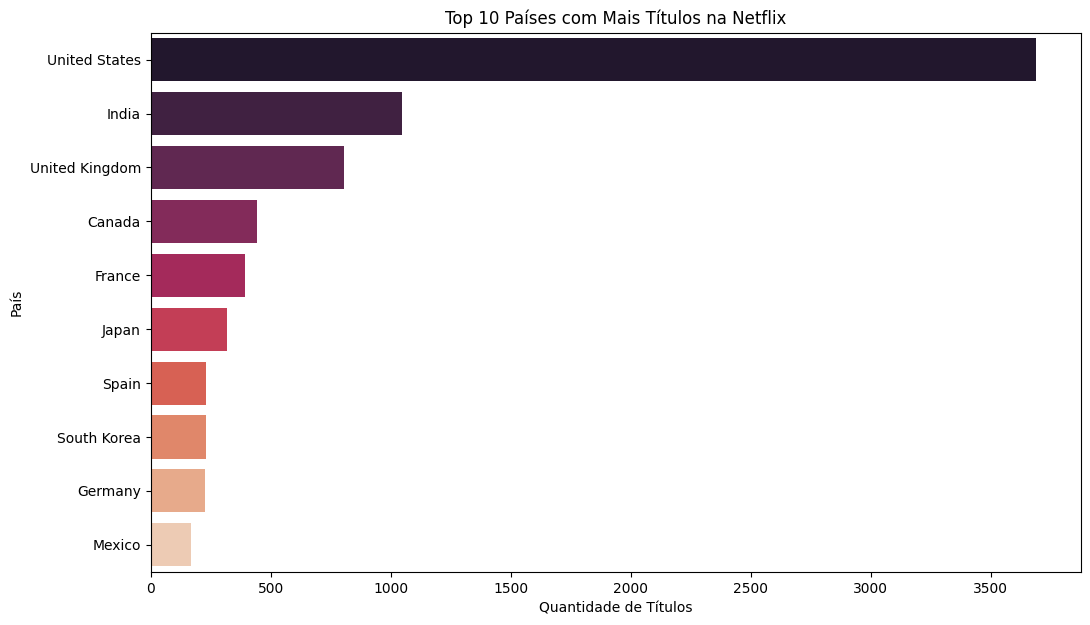

In [ ]:
# B. Países com mais Produções
#Quais são os Top 10 países que mais produziram títulos na Netflix? Crie um gráfico de barras horizontal.

df_countries = df['country'].fillna('')

# Expandir países que têm múltiplas entradas (separadas por vírgula)
# e criar uma lista de todos os países
countries_list = []
for countries in df_countries:
    for country in countries.split(','):
        country = country.strip() # Removendo os espaços em branco
        if country:
            countries_list.append(country)

# Contar a frequência de cada país
country_counts = pd.Series(countries_list).value_counts()

# Obter os Top 10 países
top_10_countries = country_counts.head(10).reset_index()
top_10_countries.columns = ['País', 'Quantidade de Títulos']

# Criar o gráfico de barras horizontal
plt.figure(figsize=(12, 7))
sns.barplot(x='Quantidade de Títulos', y='País', data=top_10_countries, palette='rocket', hue='País', legend=False)
plt.title('Top 10 Países com Mais Títulos na Netflix')
plt.xlabel('Quantidade de Títulos')
plt.ylabel('País')
plt.show()

In [ ]:
import plotly.express as px

# C. Utilize a IA Gemini para criar um gráfico de barras interativo dos 10 países com mais produções.
# Reutilizando top_10_countries do item B

fig = px.bar(top_10_countries,
             x='Quantidade de Títulos',
             y='País',
             orientation='h',
             title='Top 10 Países com Mais Títulos na Netflix (Interativo)',
             labels={'Quantidade de Títulos': 'Quantidade de Títulos', 'País': 'País'},
             color='Quantidade de Títulos',
             color_continuous_scale=px.colors.sequential.Viridis)

fig.update_layout(yaxis={'categoryorder':'total ascending'}) # Ordenar os países pelo número de títulos
fig.show()

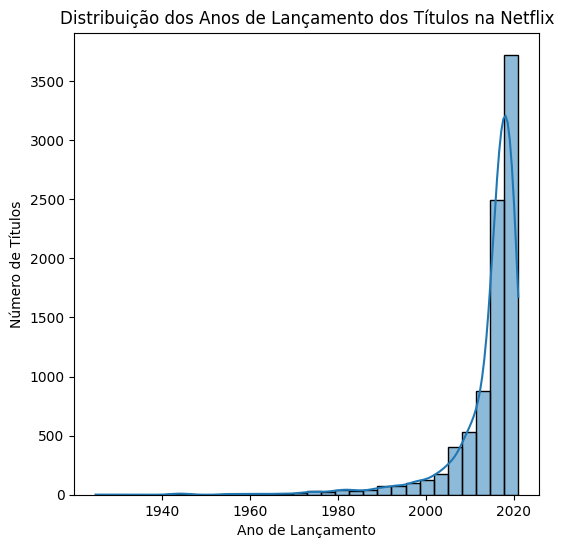

In [ ]:
# D. Distribuição do Ano de Lançamento
# Construa um histograma mostrando a distribuição dos anos de lançamento dos títulos.

plt.figure(figsize=(6, 6))
sns.histplot(df['release_year'], bins=30, kde=True)
plt.title('Distribuição dos Anos de Lançamento dos Títulos na Netflix')
plt.xlabel('Ano de Lançamento')
plt.ylabel('Número de Títulos')
plt.show()

In [ ]:
# E. Utilize a IA Gemini para criar um gráfico de pizza que represente a proporção de Filmes (tipo=Filme) por ano de lançamento, considerando somente os anos 2020 e 2021.

# Filtrar para filmes e anos 2020 e 2021
movies_2020_2021 = df[(df['type'] == 'Movie') & (df['release_year'].isin([2020, 2021]))]

# Contar a quantidade de filmes por ano
movie_counts_by_year = movies_2020_2021['release_year'].value_counts().reset_index()
movie_counts_by_year.columns = ['Ano de Lançamento', 'Quantidade de Filmes']

# Criar o gráfico de pizza interativo
fig = px.pie(movie_counts_by_year,
             names='Ano de Lançamento',
             values='Quantidade de Filmes',
             title='Proporção de Filmes Lançados em 2020 e 2021',
             color_discrete_sequence=px.colors.sequential.RdBu)

fig.update_traces(textinfo='percent+label', pull=[0.05 if year == 2021 else 0 for year in movie_counts_by_year['Ano de Lançamento']])
fig.show()

In [ ]:
import plotly.express as px

# F. Transformar o gráfico anterior em rosca.

# Reutilizando movie_counts_by_year do item E

fig = px.pie(movie_counts_by_year,
             names='Ano de Lançamento',
             values='Quantidade de Filmes',
             title='Proporção de Filmes Lançados em 2020 e 2021 (Rosca)',
             color_discrete_sequence=px.colors.sequential.RdBu,
             hole=0.5) # Adiciona o 'buraco' para transformar em rosca

fig.update_traces(textinfo='percent+label', pull=[0.05 if year == 2021 else 0 for year in movie_counts_by_year['Ano de Lançamento']])
fig.show()